In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplhep as hep
from coffea.util import load
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.decomposition import PCA

hep.style.use(hep.style.CMS)

# ==========================================
# 1. FILEPATHS & GLOBAL CONFIGURATION
# ==========================================
# Can be a single .coffea path, a list of files, or a glob pattern
SIGNAL_FILES = "Nominal2018/Sig/output_all.coffea" 
BKG_FILES    = "Nominal2018/Bkg/output_all.coffea"
# Example with globs/lists:
# SIGNAL_FILES = ["output_ttH.coffea", "output_ttZ.coffea"]
# BKG_FILES = glob.glob("bkg_outputs/*.coffea")

LUMI = 59.8 # fb^-1

MODELS = [ #"baseline",
    # "overlapRemoval_NoXbb", 
    # "overlapRemoval_FullXbb", "overlapRemoval_MultiWP",
    "noOverlap_MultiWP"
]

MODEL_COLORS = {
    "baseline": "black", "overlap_NoXbb": "#1f77b4",
    "overlapRemoval_NoXbb": "#ff7f0e", "overlapRemoval_FullXbb": "#2ca02c",
    "overlapRemoval_MultiWP": "#d62728"
}

XSEC_DICT = {
    "TTZToLLNuNu": 0.2529, "ttHTobb": 0.2934, "ttHToNonbb": 0.215,
    "TTZToQQ": 0.5297, "TTZToBB": 0.1157, "TTToHadronic": 380.095,
    "TTToSemiLeptonic": 364.018, "TTTo2L2Nu": 88.29, "TTbb_Hadronic": 9.286,
    "TTbb_SemiLeptonic": 8.168, "TTbb_2L2Nu": 1.807
}

sig_processes = ['ttZ', 'ttH']
bkg_processes = ['tt_B', 'TTBar']
all_processes = sig_processes + bkg_processes

In [2]:
def getZhbbWeight(df_):
    if 'norm_weight' not in df_.columns: 
        return pd.Series(1.0, index=df_.index) 
    weight = df_['norm_weight'].copy()
    gen_w = df_.get('genWeight', pd.Series(1.0, index=df_.index)).fillna(1.0)
    weight *= np.sign(gen_w)
    
    sfs = ['ele_reco_sf', 'ele_id_sf', 'mu_id_sf', 'mu_iso_sf', 'puWeight', 'topptWeight', 'mu_reco_sf', 'l1prefire_sf'] 
    for sf in sfs:
        weight *= df_.get(sf, pd.Series(1.0, index=df_.index)).fillna(1.0)
    return weight

def parse_single_coffea_file(filepath, is_signal_override=None):
    """Parses a single .coffea output file into a list of DataFrames."""
    filein = load(filepath)
    genweight_dict = filein.get('sum_signOf_genweights', {})
    
    # Weight variables
    base_vars = ['genWeight', 'ele_reco_sf', 'ele_id_sf', 'mu_id_sf', 'mu_iso_sf', 'puWeight', 'topptWeight', 'mu_reco_sf', 'btag_sf', 'l1prefire_sf']
    
    # --- ADDED: Cut variables needed for the mask ---
    cut_vars = ['n_ak4jets', 'n_b_outZH', 'ZH_bbvLscore', 'ZH_M']
    
    spanet_vars = []
    for m in MODELS:
        spanet_vars.extend([f"sig_score_{m}", f"ttbb_score_{m}", f"ttlf_score_{m}"])
        spanet_vars.extend([f"encoderFeature{i+1}_{m}" for i in range(32)])
        
    target_vars = base_vars + cut_vars + spanet_vars

    dfs = []
    for raw_proc, datasets in filein['columns'].items():
        mapped_proc = None
        if 'TTTo' in raw_proc: mapped_proc = 'TTBar' if 'tt+B' not in raw_proc else None
        elif 'TTbb' in raw_proc: mapped_proc = 'tt_B' if 'tt+B' in raw_proc else None
        elif 'ttH' in raw_proc or 'tth' in raw_proc.lower(): mapped_proc = 'ttH'
        elif 'TTZ' in raw_proc or 'ttz' in raw_proc.lower(): mapped_proc = 'ttZ'
        elif 'TTLL' in raw_proc or 'TTNuNu' in raw_proc: mapped_proc = 'ttZ'
        
        if is_signal_override is not None:
            is_sig_proc = is_signal_override
        else:
            if mapped_proc not in all_processes: continue
            is_sig_proc = (mapped_proc in sig_processes)
            
        for dataset, subsample_data in datasets.items():
            try:
                nom_dict = subsample_data['btag_mask']['nominal']
            except KeyError:
                continue
                
            genweight = genweight_dict.get(dataset, 1.0) 
            if isinstance(genweight, dict): 
                genweight = genweight.get(dataset, 1.0)

            tmp_data = {}
            for var in target_vars:
                dict_key = f'events_{var}'
                if dict_key in nom_dict:
                    tmp_data[var] = np.array(nom_dict[dict_key].value)
                    
            if not tmp_data: 
                continue
                
            df = pd.DataFrame(tmp_data)
            
            # --- ADDED: Apply the phase space cuts ---
            mask = (
                (df['n_ak4jets'] >= 5) &
                (df['n_b_outZH'] == 2) &
                (df['ZH_bbvLscore'] >= 0.9172) &
                (df['ZH_M'] >= 50) &
                (df['ZH_M'] <= 200)
            )
            df = df[mask].copy()
            
            if df.empty:
                continue

            # Cross section normalization
            clean_name = dataset.replace('_2018', '').replace('_2017', '').replace('_2016APV', '').replace('_2016', '')
            clean_name = clean_name.split('__')[0] 
            
            xsec = XSEC_DICT.get(clean_name, 1.0)
            calculated_norm = (xsec * LUMI * 1000) / genweight
            df['norm_weight'] = calculated_norm

            df['dataset'] = dataset
            df['process'] = mapped_proc if mapped_proc else ("signal" if is_sig_proc else "background")
            
            if is_sig_proc:
                df['plot_category'] = 'Signal_NonGenMatch' if 'non_genMatch' in raw_proc else 'Signal_GenMatch'
            else:
                df['plot_category'] = 'Background'
            
            # Apply b-tag scale factor shape normalization
            base_weight = getZhbbWeight(df)
            raw_btag_sf = df.get('btag_sf', pd.Series(1.0, index=df.index)).fillna(1.0)
            
            sum_before = np.sum(base_weight)
            sum_after = np.sum(base_weight * raw_btag_sf)
            r_ratio = sum_before / sum_after if sum_after > 0 else 1.0
            
            df['tot_weight'] = base_weight * raw_btag_sf * r_ratio
            if mapped_proc == 'tt_B': 
                df['tot_weight'] *= 1.318 # Apply tt+bb k-factor

            dfs.append(df)
            
    return dfs

def load_separate_ml_datasets(sig_inputs, bkg_inputs):
    def resolve_files(inputs):
        if isinstance(inputs, str):
            matched = glob.glob(inputs)
            return matched if matched else [inputs]
        elif isinstance(inputs, list):
            resolved = []
            for item in inputs:
                matched = glob.glob(item)
                resolved.extend(matched if matched else [item])
            return resolved
        return []

    sig_file_list = resolve_files(sig_inputs)
    bkg_file_list = resolve_files(bkg_inputs)
    
    print(f"Loading Signal from {len(sig_file_list)} file(s)...")
    sig_dfs = []
    for f in sig_file_list:
        if os.path.exists(f):
            sig_dfs.extend(parse_single_coffea_file(f, is_signal_override=True))

    print(f"Loading Background from {len(bkg_file_list)} file(s)...")
    bkg_dfs = []
    for f in bkg_file_list:
        if os.path.exists(f):
            bkg_dfs.extend(parse_single_coffea_file(f, is_signal_override=False))

    all_dfs = sig_dfs + bkg_dfs
    if not all_dfs:
        print("🚨 No data loaded!")
        return pd.DataFrame()
        
    return pd.concat(all_dfs, ignore_index=True)

df_all = load_separate_ml_datasets(SIGNAL_FILES, BKG_FILES)

for m in MODELS:
    sig  = df_all[f"sig_score_{m}"]
    ttbb = df_all[f"ttbb_score_{m}"]
    ttlf = df_all[f"ttlf_score_{m}"]
    
    denom = sig + ttbb + ttlf
    # Safe division guarding against zero denominators
    df_all[f"disc_{m}"] = np.where(denom > 0, sig / denom, 0.0)

print("Created discriminant columns:")
print([f"disc_{m}" for m in MODELS])

print("\n" + "="*45)
print(f" Total Events Passing Cuts : {len(df_all):,}")
print(f" GenMatched Signal         : {sum(df_all['plot_category'] == 'Signal_GenMatch'):,}")
print(f" NonGenMatched Signal      : {sum(df_all['plot_category'] == 'Signal_NonGenMatch'):,}")
print(f" Background Events         : {sum(df_all['plot_category'] == 'Background'):,}")
print("="*45)

Loading Signal from 1 file(s)...
Loading Background from 1 file(s)...
Created discriminant columns:
['disc_noOverlap_MultiWP']

 Total Events Passing Cuts : 269,675
 GenMatched Signal         : 89,949
 NonGenMatched Signal      : 108,061
 Background Events         : 71,665


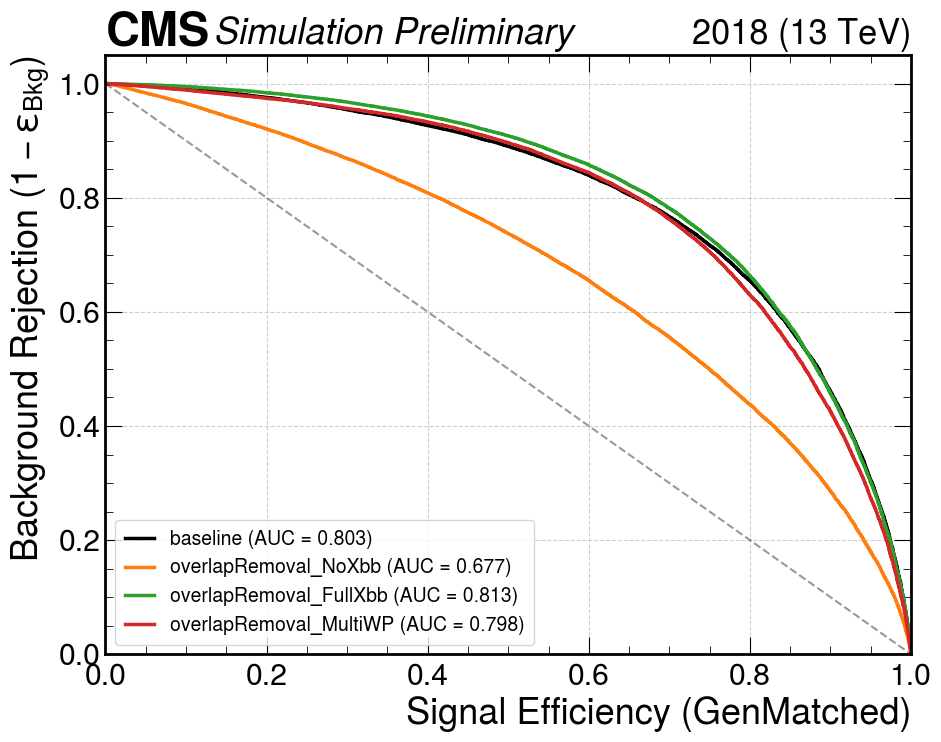

In [61]:
fig, ax = plt.subplots(figsize=(10, 8))

# Filter dataframe to exclude NonGenMatch for pure ROC evaluation
df_roc = df_all[df_all['plot_category'] != 'Signal_NonGenMatch'].copy()

# Binary classification: 1 for GenMatch Signal, 0 for Background
y_true = (df_roc['plot_category'] == 'Signal_GenMatch').astype(int).values
weights = df_roc["tot_weight"].values
valid_mask = weights > 0

for idx, model in enumerate(MODELS):
    col_name = f"disc_{model}"
    if col_name not in df_roc.columns: continue
    
    y_score = df_roc[col_name].values
    fpr, tpr, _ = roc_curve(y_true[valid_mask], y_score[valid_mask], sample_weight=weights[valid_mask])
    auc = roc_auc_score(y_true[valid_mask], y_score[valid_mask], sample_weight=weights[valid_mask])
    
    c = MODEL_COLORS.get(model, 'gray')
    ax.plot(tpr, 1.0 - fpr, label=f"{model} (AUC = {auc:.3f})", color=c, linewidth=2.5)
ax.plot([0, 1], [1, 0], "k--", alpha=0.4)
ax.set_xlabel(r"Signal Efficiency (GenMatched)")
ax.set_ylabel(r"Background Rejection ($1 - \epsilon_{\mathrm{Bkg}}$)")
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.05)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="lower left", fontsize=14, frameon=True)

hep.cms.label("Preliminary", data=False, year="2018", com=13, ax=ax)
plt.tight_layout()
plt.show()

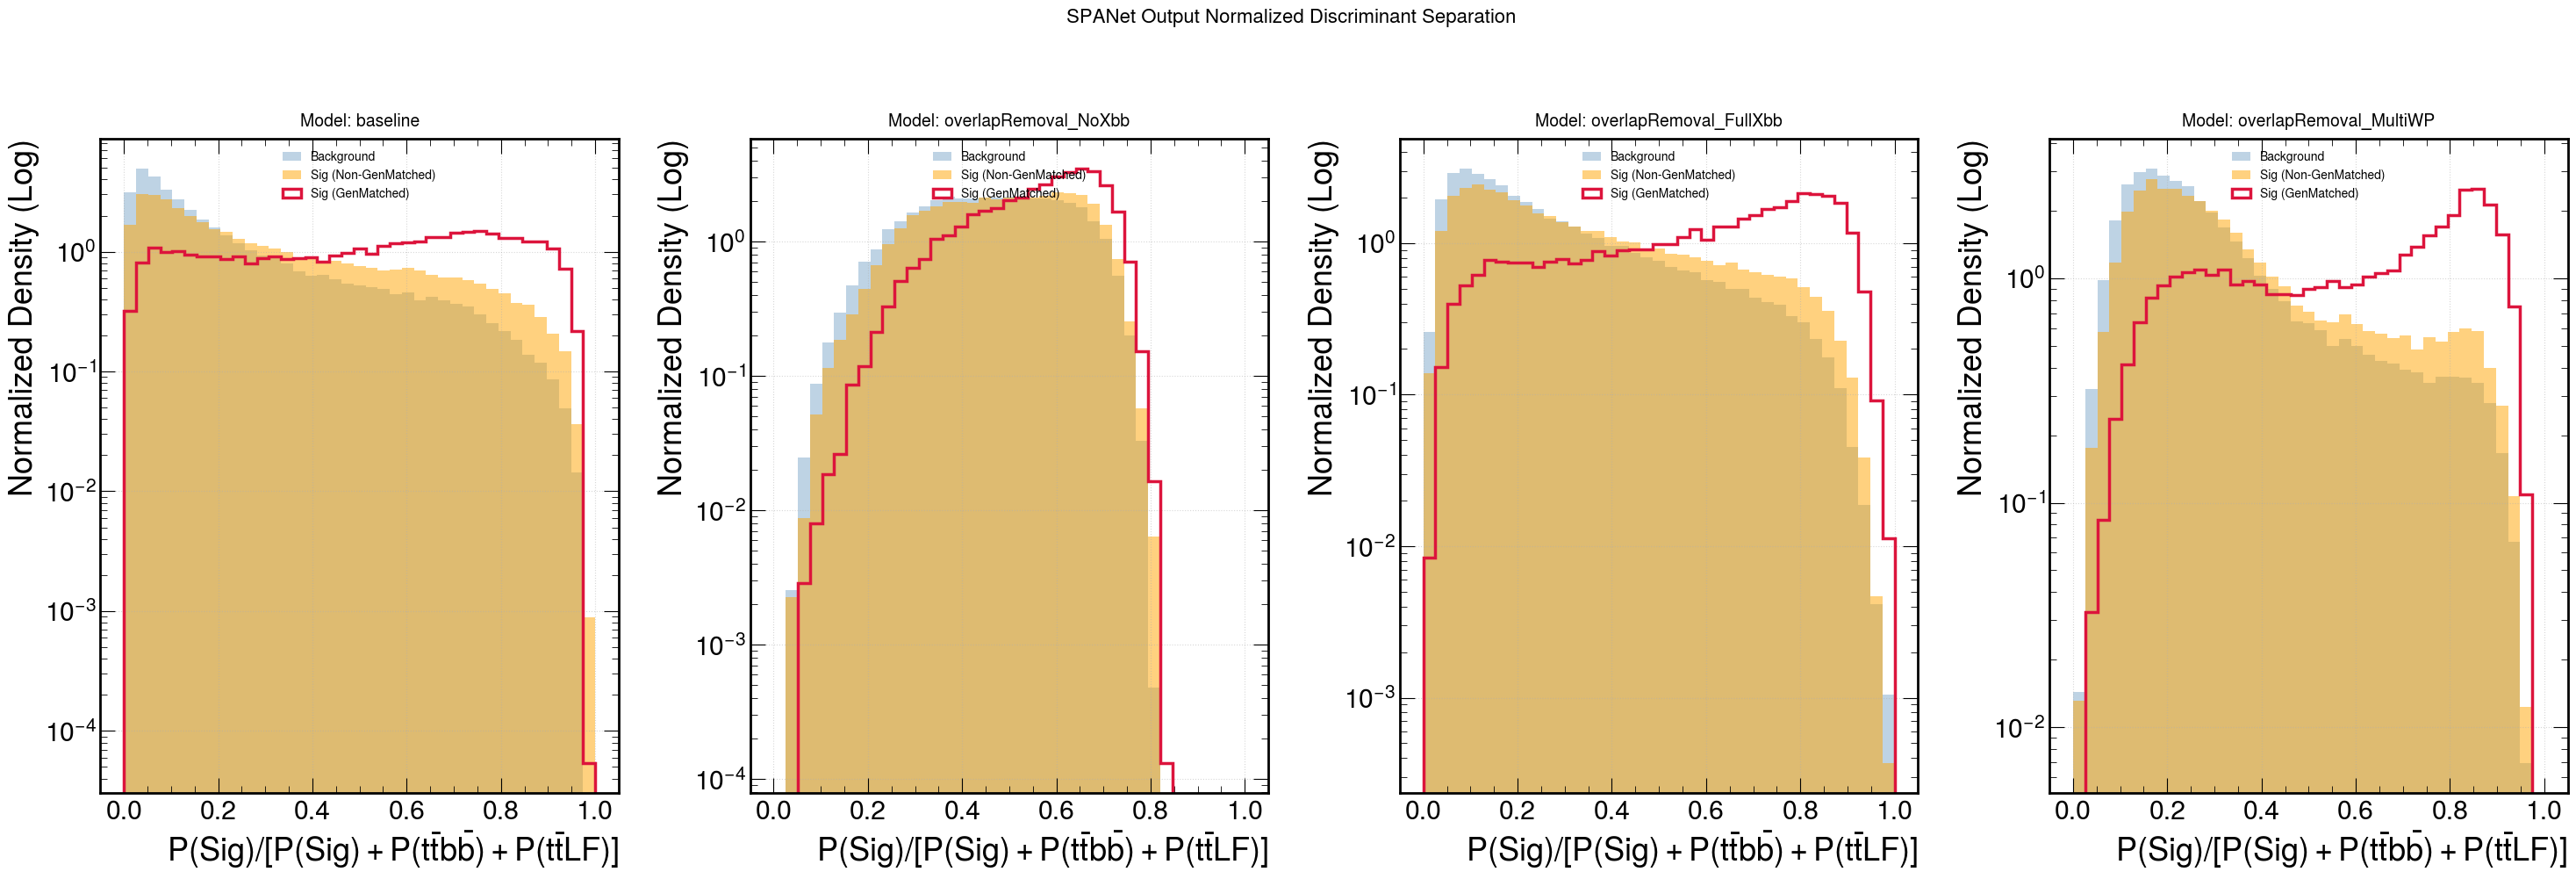

In [62]:
fig, axes = plt.subplots(1, 4, figsize=(30, 10), sharex=True)
axes = axes.flatten()

bins = np.linspace(0, 1, 40)

for idx, model in enumerate(MODELS):
    col_name = f"disc_{model}"
    if col_name not in df_all.columns: 
        continue
        
    ax = axes[idx]
    
    # Create masks
    mask_gen    = df_all["plot_category"] == "Signal_GenMatch"
    mask_nongen = df_all["plot_category"] == "Signal_NonGenMatch"
    mask_bkg    = df_all["plot_category"] == "Background"
    
    # 1. Plot Background (Solid)
    ax.hist(df_all[mask_bkg][col_name], bins=bins, weights=df_all[mask_bkg]["tot_weight"], 
            density=True, histtype="stepfilled", alpha=0.35, color="steelblue", label=r"Background")
            
    # 2. Plot Non-GenMatched Signal (Solid)
    ax.hist(df_all[mask_nongen][col_name], bins=bins, weights=df_all[mask_nongen]["tot_weight"], 
            density=True, histtype="stepfilled", alpha=0.5, color="orange", label="Sig (Non-GenMatched)")
            
    # 3. Plot GenMatched True Signal (Line overlay)
    ax.hist(df_all[mask_gen][col_name], bins=bins, weights=df_all[mask_gen]["tot_weight"], 
            density=True, histtype="step", linewidth=2.5, color="crimson", label="Sig (GenMatched)")
    
    ax.set_title(f"Model: {model}", fontsize=14, pad=10)
    ax.set_yscale("log")
    
    # Updated X-axis to reflect the new discriminant math
    ax.set_xlabel(r'$\mathrm{P(Sig)} / [\mathrm{P(Sig)} + \mathrm{P}(t\bar{t}b\bar{b}) + \mathrm{P}(t\bar{t}\mathrm{LF})]$')
    ax.set_ylabel("Normalized Density (Log)")
    ax.legend(loc="upper center", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.5)

# Dynamically hide any unused subplots (e.g., the 6th empty plot)
for idx in range(len(MODELS), len(axes)):
    fig.delaxes(axes[idx])

plt.suptitle("SPANet Output Normalized Discriminant Separation", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [63]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
from matplotlib.backends.backend_pdf import PdfPages

# --- Missing Dictionary Definitions ---
bkg_processes = ['tt_B', 'TTBar', 'VJets', 'QCD', 'SingleTop', 'TTX'] 
sig_processes = ['ttZ', 'ttH']

bkg_colors = {'VJets':'#3f90da', 'QCD':'#ffa90e', 'tt_B':'#bd1f01', 'TTBar':'#94a4a2', 'SingleTop':'#e76300', 'TTX':'#b9ac70'}
sig_colors = {'ttZ':'#832db6', 'ttH':'#a96b59'}
mc_colors = {**bkg_colors, **sig_colors}

process_labels = {
    'VJets': 'V+Jets', 'QCD': 'QCD', 'tt_B': r'$t\bar{t}+b\bar{b}$',
    'TTBar': r'$t\bar{t} + \mathrm{LF}, t\bar{t}+c\bar{c}$', 'SingleTop': 'single top',
    'TTX': r'$t\bar{t}t\bar{t}, t\bar{t}W, t\bar{t}HW, t\bar{t}Hq$',
    'ttZ': r'$t\bar{t}Z$', 'ttH': r'$t\bar{t}H$', 'data_obs': 'Data', 'VV': 'VV'
}
# --------------------------------------

def weighted_quantile(values, quantiles, sample_weight=None, values_sorted=False, old_style=False):
    """ Computes weighted quantiles. """
    values = np.array(values)
    quantiles = np.array(quantiles)
    if sample_weight is None:
        sample_weight = np.ones(len(values))
    sample_weight = np.array(sample_weight)
    assert np.all(quantiles >= 0) and np.all(quantiles <= 1), 'quantiles should be in [0, 1]'

    if not values_sorted:
        sorter = np.argsort(values)
        values = values[sorter]
        sample_weight = sample_weight[sorter]

    weighted_quantiles = np.asarray(np.cumsum(sample_weight) - 0.5 * sample_weight)
    if old_style:
        weighted_quantiles -= weighted_quantiles[0]
        weighted_quantiles /= weighted_quantiles[-1]
    else:
        weighted_quantiles /= np.sum(sample_weight)
    return np.interp(quantiles, weighted_quantiles, values)

def plot_quantile_distributions(df, models_list, output_filename="SPANet_Quantile_SoB.pdf"):
    print(f"\n--- Generating Quantile S/sqrt(B) Plots ---")
    
    quantiles = [0.0, 0.05, 0.25, 0.35, 0.50, 0.70, 1.0]
    
    df_sig_gen = df[df['plot_category'] == 'Signal_GenMatch'].copy()
    df_bkg = df[df['plot_category'] == 'Background'].copy()
    
    if df_sig_gen.empty:
        print("Error: No GenMatched signal found in dataframe.")
        return
        
    summary_stats = {}
    
    with PdfPages(output_filename) as pdf:
        for model in models_list:
            # Use the calculated ratio
            col_name = f"disc_{model}"
            if col_name not in df.columns: 
                print(f"Warning: {col_name} missing from DataFrame. Skipping.")
                continue
                
            # 1. Calculate Quantile Bins using GenMatched Signal
            sig_scores = df_sig_gen[col_name].values
            sig_weights = df_sig_gen['tot_weight'].values
            
            nn_bins = weighted_quantile(sig_scores, quantiles, sample_weight=sig_weights)
            nn_bins[0], nn_bins[-1] = 0.0, 1.0
            nn_bins = np.unique(nn_bins) 
            
            # 2. Setup Figure
            fig, (ax, ax2) = plt.subplots(2, 1, sharex=True, gridspec_kw={'height_ratios': [3, 1]})
            fig.set_size_inches(6, 6)
            
            sumS = np.zeros(len(nn_bins) - 1)
            sumB = np.zeros(len(nn_bins) - 1)
            
            # 3. Plot Backgrounds (UNSTACKED)
            for proc in bkg_processes:
                proc_df = df_bkg[df_bkg['process'] == proc]
                if proc_df.empty: continue
                    
                counts, _ = np.histogram(proc_df[col_name], bins=nn_bins, weights=proc_df['tot_weight'])
                sumB += counts
                
                hep.histplot(counts, bins=nn_bins, ax=ax, stack=False, histtype='step', 
                             linewidth=2, label=process_labels.get(proc, proc), 
                             color=mc_colors.get(proc, 'gray'))

            # 4. Plot Signals (UNSTACKED)
            for proc in sig_processes:
                proc_df = df_sig_gen[df_sig_gen['process'] == proc]
                if proc_df.empty: continue
                    
                counts, _ = np.histogram(proc_df[col_name], bins=nn_bins, weights=proc_df['tot_weight'])
                sumS += counts
                
                hep.histplot(counts, bins=nn_bins, ax=ax, stack=False, histtype='step', 
                             linewidth=2, label=process_labels.get(proc, proc) + r"$_{matched}$", 
                             color=mc_colors.get(proc, 'black'))

            # 5. Calculate and Plot S / sqrt(B)
            bin_centers = 0.5 * (nn_bins[1:] + nn_bins[:-1])
            bin_widths = (nn_bins[1:] - nn_bins[:-1]) / 2
            
            with np.errstate(divide='ignore', invalid='ignore'):
                s_sqrt_b = np.where(sumB > 0, sumS / np.sqrt(sumB), 0)
                
            ax2.errorbar(x=bin_centers, y=s_sqrt_b, xerr=bin_widths, fmt='.', color='k', label=r'S/$\sqrt{\mathrm{B}}$')
            
            # Store stats for the summary table
            summary_stats[model] = {
                'bins': nn_bins,
                'S': sumS,
                'B': sumB,
                'S_sqrt_B': s_sqrt_b
            }
            
            # 6. Styling & Labels
            ax.set_yscale('log')
            ax.set_xlim([0.0, 1.0]) 
            
            all_counts = sumS + sumB
            #if np.any(all_counts > 0):
            #    ax.set_ylim(bottom=max(0.01, np.min(all_counts[all_counts>0]) * 0.1))
            
            ax.set_ylabel("Events")
            ax2.set_ylabel(r'$\mathrm{S/}\sqrt{\mathrm{B}}$', fontsize=12)
            ax2.set_xlabel(r'$\mathrm{P(Sig)} / [\mathrm{P(Sig)} + \mathrm{P}(t\bar{t}b\bar{b}) + \mathrm{P}(t\bar{t}\mathrm{LF})]$', fontsize=11)
            
            ax.tick_params(which='both', direction='in', top=True, right=True)
            ax2.tick_params(which='both', direction='in', top=True, right=True)
            ax2.grid(True, linestyle="--", alpha=0.5)
            
            ax.legend(framealpha=0.0, ncol=2, fontsize=10, loc='upper left')
            
            # --- ADDED: Print the model name inside the plot ---
            ax.text(0.95, 0.95, f"Model: {model}", transform=ax.transAxes, 
                    fontsize=14, fontweight='bold', va='top', ha='right')
            # ---------------------------------------------------
            
            hep.cms.label(label="Preliminary", data=False, lumi=LUMI, ax=ax, com=13.6, fontsize=12)
            fig.subplots_adjust(hspace=0.05)
            
            pdf.savefig(fig, bbox_inches='tight')
            plt.close(fig)
            
    print(f"Saved quantile plots to {output_filename}")
    
    # Print Summary Table
    print("\n" + "="*60)
    print(" MODEL COMPARISON SUMMARY (Normalized Discriminant)")
    print("="*60)
    for model, stats in summary_stats.items():
        print(f"\nModel: {model.upper()}")
        print("-" * 60)
        print(f"{'Bin Range':<20} | {'S':<8} | {'B':<8} | {'S/sqrt(B)':<10}")
        print("-" * 60)
        for i in range(len(stats['S'])):
            bin_str = f"[{stats['bins'][i]:.3f} - {stats['bins'][i+1]:.3f}]"
            marker = " <--" if i >= len(stats['S']) - 2 else ""
            print(f"{bin_str:<20} | {stats['S'][i]:<8.2f} | {stats['B'][i]:<8.2f} | {stats['S_sqrt_B'][i]:<10.3f}{marker}")
        print("-" * 60)
        print(f"Maximum Single-Bin S/sqrt(B): {np.max(stats['S_sqrt_B']):.3f}")
    print("="*60 + "\n")

plot_quantile_distributions(df_all, MODELS)


--- Generating Quantile S/sqrt(B) Plots ---
Saved quantile plots to SPANet_Quantile_SoB.pdf

 MODEL COMPARISON SUMMARY (Normalized Discriminant)

Model: BASELINE
------------------------------------------------------------
Bin Range            | S        | B        | S/sqrt(B) 
------------------------------------------------------------
[0.000 - 0.072]      | 2.93     | 697.51   | 0.111     
[0.072 - 0.286]      | 11.70    | 841.47   | 0.403     
[0.286 - 0.398]      | 5.85     | 162.85   | 0.459     
[0.398 - 0.555]      | 8.78     | 145.84   | 0.727     
[0.555 - 0.712]      | 11.70    | 102.12   | 1.158      <--
[0.712 - 1.000]      | 17.56    | 67.20    | 2.142      <--
------------------------------------------------------------
Maximum Single-Bin S/sqrt(B): 2.142

Model: OVERLAPREMOVAL_NOXBB
------------------------------------------------------------
Bin Range            | S        | B        | S/sqrt(B) 
------------------------------------------------------------
[0.000 - 0.

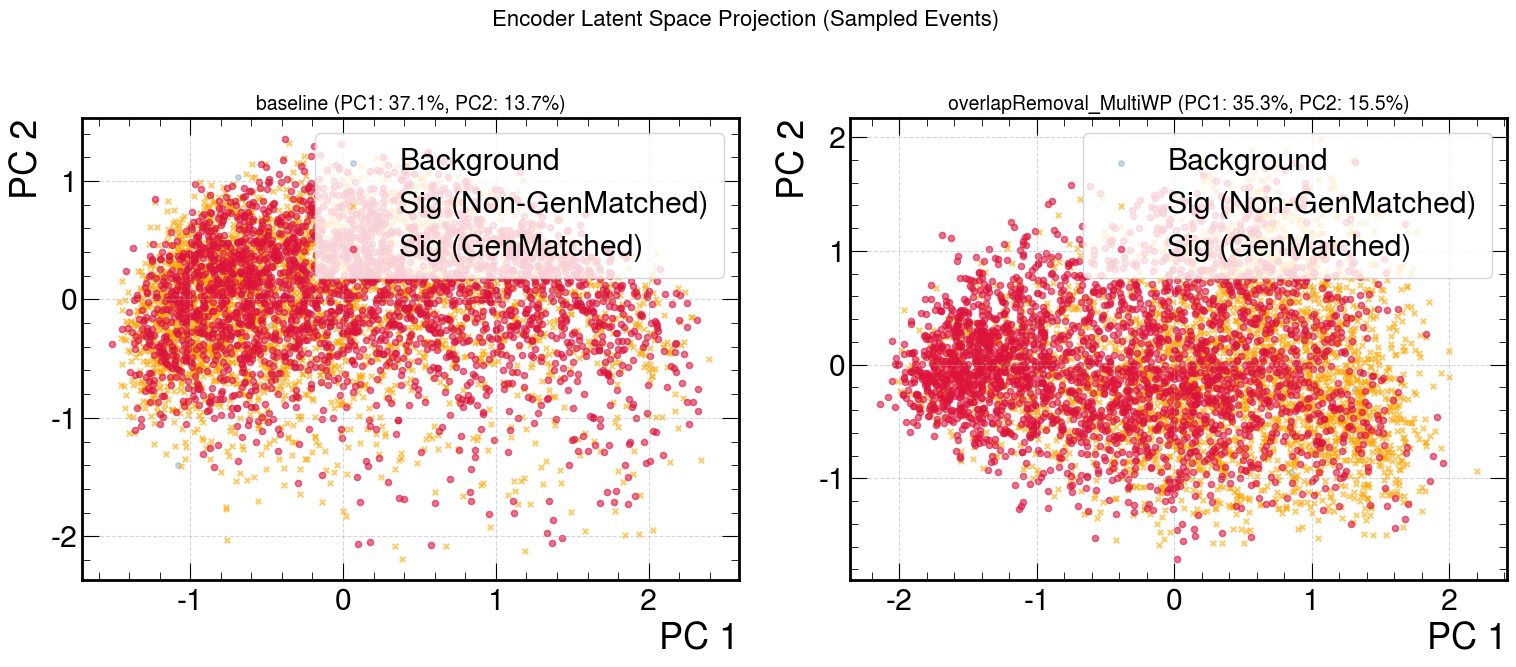

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
comparison_models = ["baseline", "overlapRemoval_MultiWP"]

for ax, model in zip(axes, comparison_models):
    enc_cols = [f"encoderFeature{i+1}_{model}" for i in range(32)]
    if enc_cols[0] not in df_all.columns: continue
        
    sub_df = df_all.sample(n=min(6000, len(df_all)), random_state=42)
    features = sub_df[enc_cols].values
    
    pca = PCA(n_components=2)
    latent_2d = pca.fit_transform(features)
    
    mask_gen    = sub_df["plot_category"] == "Signal_GenMatch"
    mask_nongen = sub_df["plot_category"] == "Signal_NonGenMatch"
    mask_bkg    = sub_df["plot_category"] == "Background"
    
    ax.scatter(latent_2d[mask_bkg, 0], latent_2d[mask_bkg, 1], 
               c="steelblue", alpha=0.3, s=15, label=r"Background")
               
    ax.scatter(latent_2d[mask_nongen, 0], latent_2d[mask_nongen, 1], 
               c="orange", alpha=0.6, s=15, marker='x', label="Sig (Non-GenMatched)")
               
    ax.scatter(latent_2d[mask_gen, 0], latent_2d[mask_gen, 1], 
               c="crimson", alpha=0.6, s=20, label="Sig (GenMatched)")
    
    var_exp = pca.explained_variance_ratio_ * 100
    ax.set_title(f"{model} (PC1: {var_exp[0]:.1f}%, PC2: {var_exp[1]:.1f}%)", fontsize=14)
    ax.set_xlabel("PC 1")
    ax.set_ylabel("PC 2")
    ax.legend(frameon=True, loc="upper right")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Encoder Latent Space Projection (Sampled Events)", fontsize=16)
plt.tight_layout()
plt.show()